# Uçuş Gecikmesi Tahmini — 3. Keşifsel veri analizi (EDA)
Sunumdaki bulgu grafikleri bu notebook'tan çıkıyor. Her grafik Drive'da `UcusGecikme/figures/` klasörüne PNG olarak kaydediliyor.

**Ön koşul:** `02_temizlik_birlestirme` çalışmış olmalı (`processed/flights_2025_clean.parquet`).

Not: Gecikme oranları **tamamlanan uçuşlar** üzerinden (iptal / yön değiştiren uçuşların target'ı yok).
Bu notebook'ta `post_` sütunlarını (gecikme sebepleri vb.) **sadece analiz için** kullanıyoruz; modele girmeyecekler.

Çalışma zamanı → Tümünü çalıştır (2–3 dakika). Bitince .ipynb olarak indirip gönder.

## 0. Kurulum ve grafik stili

In [1]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'duckdb'], check=False)

from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/UcusGecikme')
except ImportError:
    BASE = Path('.')
DATA = BASE / 'processed' / 'flights_2025_clean.parquet'
FIG = BASE / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 200)

con = duckdb.connect()
con.sql(f"CREATE VIEW f AS SELECT * FROM '{DATA}'")
con.sql("CREATE VIEW t AS SELECT * FROM f WHERE status = 'tamamlandi'")
BASE_RATE = con.sql('SELECT avg(target_arr_del15) FROM t').fetchone()[0]
print(f'Genel gecikme oranı (tamamlanan uçuşlar): %{BASE_RATE * 100:.1f}')

# Renkler: tek seri = mavi; vurgu (en kötü / en iyi) = turuncu; metin her zaman gri tonlarında
BLUE, ORANGE, MUTED_BAR = '#2a78d6', '#eb6834', '#a9c7ee'
INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e6e5e0', '#fcfcfb'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': GRID, 'grid.linewidth': 0.8,
    'font.size': 11, 'axes.titlesize': 14, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.titlecolor': INK, 'figure.dpi': 110,
})
PCT = mtick.PercentFormatter(1.0, decimals=0)


def fmt_n(n):
    return f'{n / 1e6:.1f} milyon'.replace('.', ',') if n >= 1e6 else (f'{n / 1000:,.0f} bin' if n >= 1000 else f'{n:,}')


def finish(fig, ax, name, subtitle=None, source=True):
    if subtitle:
        ax.set_title(ax.get_title(loc='left'), loc='left', pad=34)
        ax.text(0, 1.05, subtitle, transform=ax.transAxes, color=INK2, fontsize=10.5, va='bottom')
    if source:
        fig.text(0.01, 0.005, 'Kaynak: BTS 2025 (Kaggle) + NOAA GHCN-Daily (AWS) · tamamlanan uçuşlar', color=INK2, fontsize=8.5)
    fig.tight_layout(rect=(0, 0.02, 1, 1))
    fig.savefig(FIG / f'{name}.png', dpi=200, bbox_inches='tight')
    plt.show()
    print(f'Kaydedildi: figures/{name}.png')


def baseline(ax, horizontal=False):
    (ax.axvline if horizontal else ax.axhline)(BASE_RATE, color=INK2, lw=1, ls='--', zorder=1)
    if horizontal:
        ax.text(BASE_RATE, 1.0, ' ortalama %' + f'{BASE_RATE * 100:.1f}'.replace('.', ','), transform=ax.get_xaxis_transform(),
                color=INK2, fontsize=9, va='bottom')
    else:
        ax.text(1.0, BASE_RATE, 'ortalama %' + f'{BASE_RATE * 100:.1f}'.replace('.', ',') + ' ', transform=ax.get_yaxis_transform(),
                color=INK2, fontsize=9, ha='right', va='bottom')

Mounted at /content/drive


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Genel gecikme oranı (tamamlanan uçuşlar): %22.3


## 1. Target'ı anlamak: varış gecikmesi dağılımı
Target "15 dakikadan fazla gecikti mi?" Önce gecikme dakikalarının nasıl dağıldığına bakalım.

Erken inen uçuş: %60.1   Medyan: -6 dk   15 dk+ gecikme: %22.8


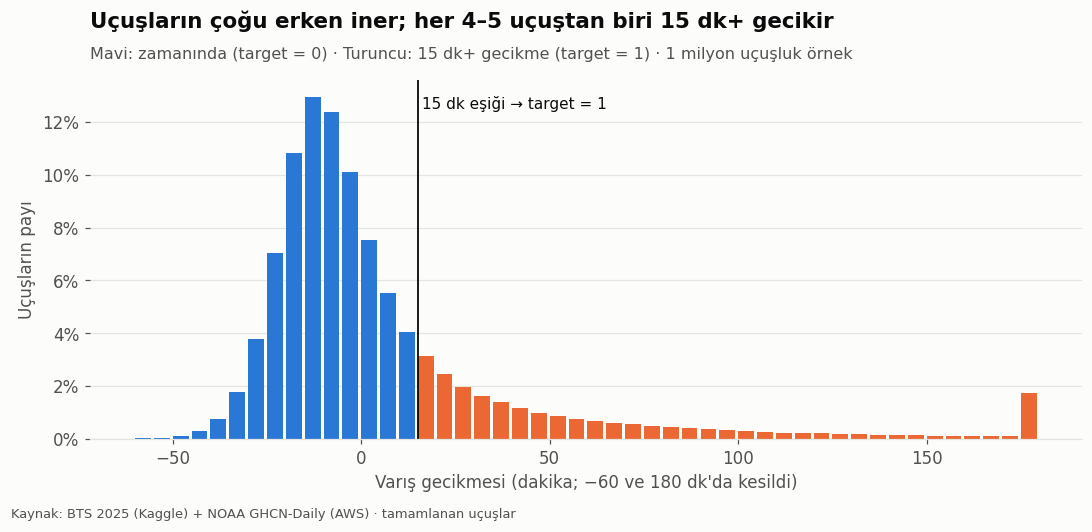

Kaydedildi: figures/01_gecikme_dagilimi.png


In [2]:
d = con.sql('''SELECT greatest(least(post_arr_delay_min, 180), -60) AS m FROM t USING SAMPLE 1000000 ROWS''').df()['m']
print(f'Erken inen uçuş: %{(d < 0).mean() * 100:.1f}   Medyan: {d.median():.0f} dk   15 dk+ gecikme: %{(d >= 15).mean() * 100:.1f}')
fig, ax = plt.subplots(figsize=(10, 4.8))
bins = np.arange(-60, 185, 5)
counts, edges = np.histogram(d, bins=bins)
colors = [ORANGE if e >= 15 else BLUE for e in edges[:-1]]
ax.bar(edges[:-1], counts / counts.sum(), width=4.2, align='edge', color=colors, zorder=2)
ax.axvline(15, color=INK, lw=1.2)
ax.text(16, ax.get_ylim()[1] * 0.92, '15 dk eşiği → target = 1', color=INK, fontsize=10)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlabel('Varış gecikmesi (dakika; −60 ve 180 dk\'da kesildi)')
ax.set_ylabel('Uçuşların payı')
ax.set_title('Uçuşların çoğu erken iner; her 4–5 uçuştan biri 15 dk+ gecikir')
finish(fig, ax, '01_gecikme_dagilimi', subtitle='Mavi: zamanında (target = 0) · Turuncu: 15 dk+ gecikme (target = 1) · 1 milyon uçuşluk örnek')

**Yorum — target'ı anlamak**
- Uçuşların **%60'ı erken iniyor**, medyan varış gecikmesi **−5 dakika**. Havayolları tarifeye pay koyuyor ("schedule padding").
- 15 dk eşiğinin sağındaki turuncu kuyruk uzun: gecikme olduğunda genelde büyük oluyor (180 dk'daki çubuk, 3 saat ve üstü gecikmelerin toplandığı yer).
- Bu yüzden problemi **"kaç dakika gecikecek?"** (regresyon, uç değerlere çok duyarlı) yerine **"15 dk'yı geçecek mi?"** (sınıflandırma) olarak kurmak hem istatistiksel olarak sağlam hem de iş açısından anlamlı: BTS'nin resmî "dakiklik" tanımı da bu eşik.
- Sınıf oranı ≈ **%22 / %78** → dengesiz ama aşırı değil. Değerlendirmede accuracy yerine **ROC-AUC, PR-AUC, recall ve F1** kullanacağız.

## 2. Zaman: aylar ve gün içindeki saat

 month   ucus  oran
     1 522269  18.8
     2 496476  20.8
     3 592301  19.6
     4 577730  19.7
     5 597574  23.6
     6 599472  28.3
     7 612811  28.9
     8 593733  22.6
     9 558329  16.6
    10 601570  20.3
    11 555296  20.6
    12 571924  26.8


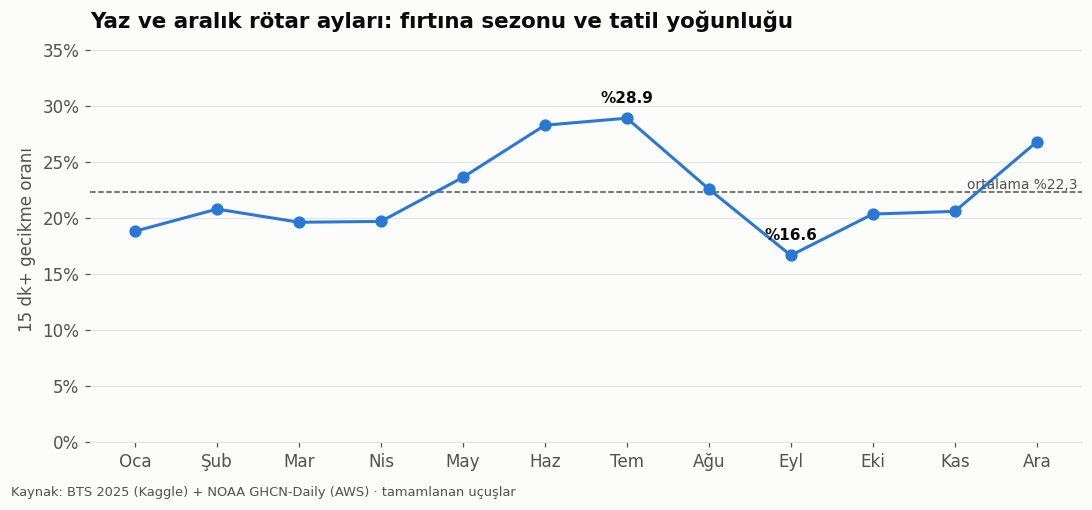

Kaydedildi: figures/02_aylara_gore.png


In [3]:
m = con.sql('''SELECT month, count(*) AS ucus, avg(target_arr_del15) AS oran FROM t GROUP BY 1 ORDER BY 1''').df()
print(m.assign(oran=(m['oran'] * 100).round(1)).to_string(index=False))
AYLAR = ['Oca', 'Şub', 'Mar', 'Nis', 'May', 'Haz', 'Tem', 'Ağu', 'Eyl', 'Eki', 'Kas', 'Ara']
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.plot(m['month'], m['oran'], color=BLUE, lw=2, marker='o', ms=7, zorder=3)
for i in (m['oran'].idxmax(), m['oran'].idxmin()):
    ax.annotate(f"%{m.at[i, 'oran'] * 100:.1f}", (m.at[i, 'month'], m.at[i, 'oran']), textcoords='offset points',
                xytext=(0, 10), ha='center', color=INK, fontsize=10, fontweight='bold')
baseline(ax)
ax.set_xticks(range(1, 13), AYLAR)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, m['oran'].max() * 1.25)
ax.set_ylabel('15 dk+ gecikme oranı')
ax.set_title('Yaz ve aralık rötar ayları: fırtına sezonu ve tatil yoğunluğu')
finish(fig, ax, '02_aylara_gore')

 dep_hour   ucus  oran
        0  11076  16.5
        5 194931   8.9
        6 474704  10.1
        7 501217  12.7
        8 478909  14.5
        9 390739  15.8
       10 427414  17.3
       11 431894  19.4
       12 408052  21.1
       13 410959  22.7
       14 397468  25.8
       15 394967  27.9
       16 394921  29.7
       17 432324  31.2
       18 408988  31.8
       19 373468  32.6
       20 303871  31.8
       21 229222  29.1
       22 153112  28.8
       23  55527  20.0


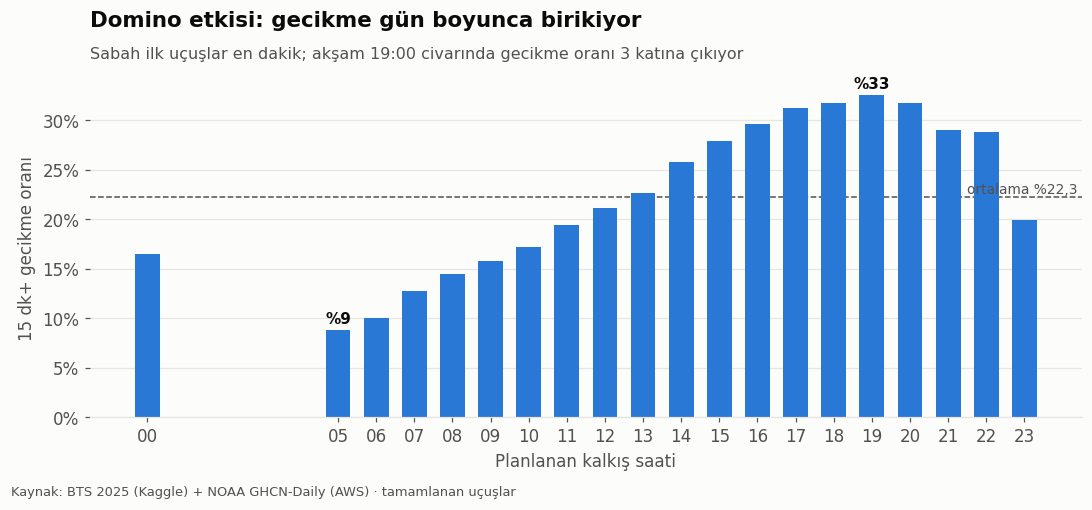

Kaydedildi: figures/03_saate_gore.png


In [4]:
h = con.sql('''SELECT dep_hour, count(*) AS ucus, avg(target_arr_del15) AS oran FROM t GROUP BY 1 ORDER BY 1''').df()
h = h[h['ucus'] >= h['ucus'].sum() * 0.001]  # uçuşların %0,1'inden azının olduğu gece saatlerini çizmiyoruz
print(h.assign(oran=(h['oran'] * 100).round(1)).to_string(index=False))
fig, ax = plt.subplots(figsize=(10, 4.6))
ax.bar(h['dep_hour'], h['oran'], width=0.65, color=BLUE, zorder=2)
for hr in (h.loc[h['oran'].idxmin(), 'dep_hour'], h.loc[h['oran'].idxmax(), 'dep_hour']):
    r = h[h['dep_hour'] == hr].iloc[0]
    ax.text(hr, r['oran'] + 0.006, f"%{r['oran'] * 100:.0f}", ha='center', color=INK, fontsize=10, fontweight='bold')
baseline(ax)
ax.set_xticks(h['dep_hour'], [f'{x:02d}' for x in h['dep_hour']])
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel('Planlanan kalkış saati')
ax.set_ylabel('15 dk+ gecikme oranı')
ax.set_title('Domino etkisi: gecikme gün boyunca birikiyor')
finish(fig, ax, '03_saate_gore', subtitle='Sabah ilk uçuşlar en dakik; akşam 19:00 civarında gecikme oranı 3 katına çıkıyor')

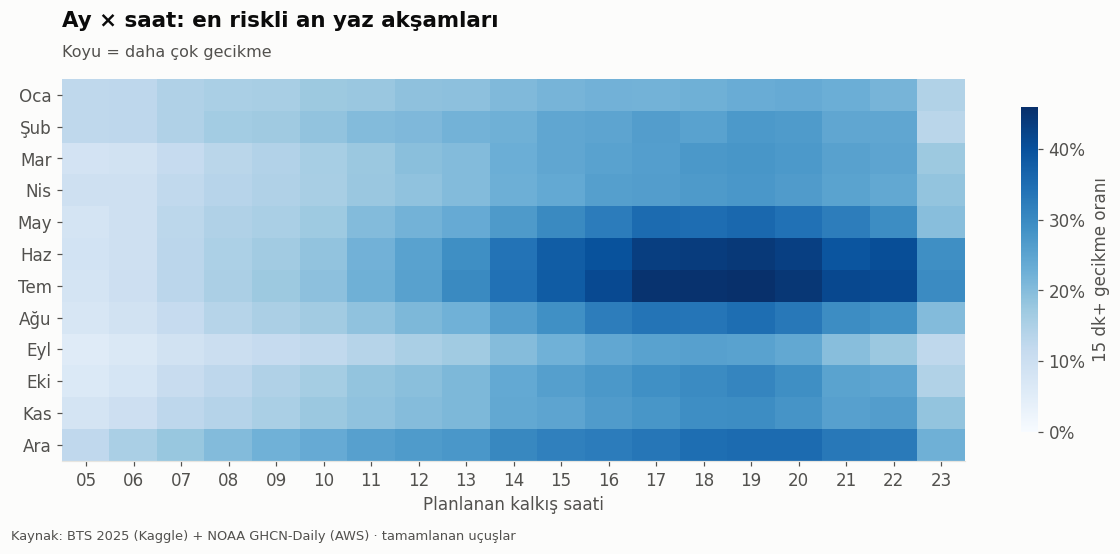

Kaydedildi: figures/04_ay_saat_isi_haritasi.png


In [5]:
hm = con.sql('''SELECT month, dep_hour, avg(target_arr_del15) AS oran, count(*) AS n FROM t
                WHERE dep_hour BETWEEN 5 AND 23 GROUP BY 1, 2''').df()
grid = hm.pivot(index='month', columns='dep_hour', values='oran')
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(grid.values, aspect='auto', cmap='Blues', vmin=0, vmax=np.nanmax(grid.values))
ax.set_xticks(range(grid.shape[1]), [f'{c:02d}' for c in grid.columns])
ax.set_yticks(range(12), AYLAR)
ax.grid(False)
ax.set_xlabel('Planlanan kalkış saati')
cb = fig.colorbar(im, ax=ax, format=PCT, shrink=0.85)
cb.set_label('15 dk+ gecikme oranı', color=INK2)
cb.outline.set_visible(False)
ax.set_title('Ay × saat: en riskli an yaz akşamları')
finish(fig, ax, '04_ay_saat_isi_haritasi', subtitle='Koyu = daha çok gecikme')

**Yorum — zaman**
- **Aylar:** Haziran–Temmuz (%28–29) ve Aralık (%27) zirve; Eylül (%16,6) en dakik ay. Yaz: gök gürültülü fırtına sezonu + tatil trafiği. Aralık: kış koşulları + yılbaşı yoğunluğu. Eylül: okullar açılmış, trafik düşük, hava sakin.
- **Saat (en güçlü bulgu — domino etkisi):** 05:00 kalkışlarda gecikme **%8,9**, 19:00'da **%32,6** — yaklaşık **4 kat**. Bir uçak gün içinde 4–6 sefer yapıyor; sabahki küçük bir gecikme sonraki seferlere taşınıyor ve birikiyor. Bölüm 5'teki "uçağın önceki seferi geç geldi" sebebinin en büyük pay (%39) olması bunu doğruluyor.
- **Isı haritası:** İki etki üst üste biniyor → en riskli an **yaz akşamları** (Haziran–Temmuz, 17:00–20:00, ≈ %45); en güvenli an **sonbahar sabahları**.
- **Öneri (yolcu):** Önemli bir bağlantı/toplantı varsa sabah ilk seferi seçin. **Öneri (havayolu):** Yaz akşam bloklarında tarifeye daha fazla tampon süre / yedek uçak.

## 3. Havayolları ve havalimanları

airline    ucus  oran             ad
     HA   79335  17.3  Hawaiian (HA)
     DL 1012427  19.8     Delta (DL)
     OO  825202  20.7   SkyWest (OO)
     MQ  291835  21.0     Envoy (MQ)
     WN 1376837  21.4 Southwest (WN)
     NK  191191  21.4    Spirit (NK)
     UA  786377  21.5    United (UA)
     YX  334044  21.5  Republic (YX)
     AS  241927  23.1    Alaska (AS)
     G4  129892  25.0 Allegiant (G4)
     AA  952841  25.7  American (AA)
     B6  226703  26.2   JetBlue (B6)
     OH  236682  27.5       PSA (OH)
     F9  194192  27.9  Frontier (F9)


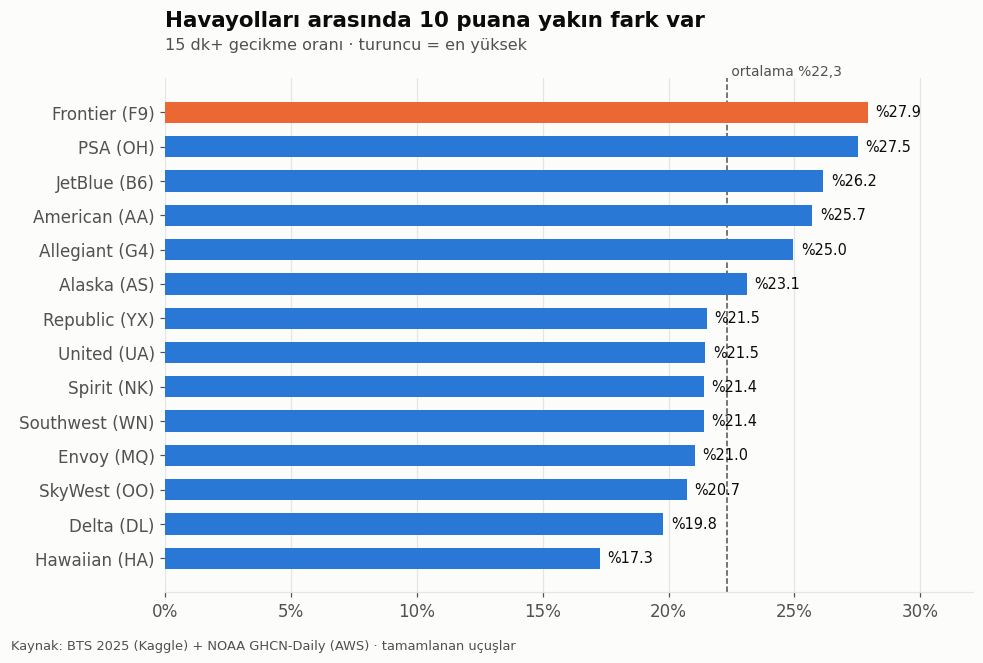

Kaydedildi: figures/05_havayollari.png


In [6]:
AIRLINES = {'WN': 'Southwest', 'DL': 'Delta', 'AA': 'American', 'OO': 'SkyWest', 'UA': 'United', 'YX': 'Republic',
            'MQ': 'Envoy', 'OH': 'PSA', 'AS': 'Alaska', 'B6': 'JetBlue', 'F9': 'Frontier', 'NK': 'Spirit',
            'G4': 'Allegiant', 'HA': 'Hawaiian', '9E': 'Endeavor', 'QX': 'Horizon', 'ZW': 'Air Wisconsin'}
a = con.sql('''SELECT airline, count(*) AS ucus, avg(target_arr_del15) AS oran FROM t GROUP BY 1 ORDER BY oran''').df()
a['ad'] = a['airline'].map(AIRLINES).fillna(a['airline']) + ' (' + a['airline'] + ')'
print(a.assign(oran=(a['oran'] * 100).round(1)).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 6))
colors = [ORANGE if i == len(a) - 1 else BLUE for i in range(len(a))]
ax.barh(a['ad'], a['oran'], height=0.62, color=colors, zorder=2)
for y, (v, n) in enumerate(zip(a['oran'], a['ucus'])):
    ax.text(v + 0.003, y, f'%{v * 100:.1f}', va='center', color=INK, fontsize=9.5)
baseline(ax, horizontal=True)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, a['oran'].max() * 1.15)
ax.set_title('Havayolları arasında 10 puana yakın fark var')
finish(fig, ax, '05_havayollari', subtitle='15 dk+ gecikme oranı · turuncu = en yüksek')

origin   ucus  oran
   SLC 115369  15.8
   LAX 188578  17.6
   PHX 194840  19.6
   SFO 142973  19.8
   MSP 111700  20.3
   LAS 181901  20.8
   DTW 120881  21.8
   SEA 162971  22.2
   IAH 115404  22.8
   ATL 309064  24.0
   BOS 140092  24.2
   MCO 157950  24.5
   CLT 191629  24.7
   EWR 116940  25.3
   DEN 314281  25.7
   MIA 110113  26.0
   LGA 131177  26.4
   ORD 320418  26.5
   DCA 136684  27.1
   DFW 306185  28.7


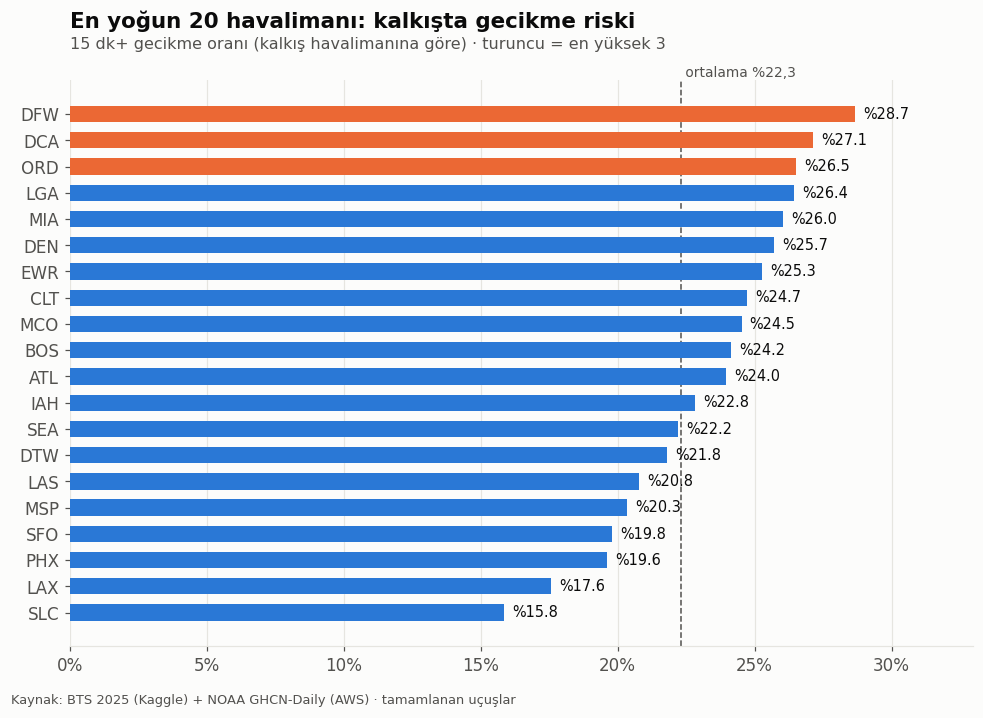

Kaydedildi: figures/06_havalimanlari.png


In [7]:
ap = con.sql('''SELECT origin, count(*) AS ucus, avg(target_arr_del15) AS oran FROM t
                GROUP BY 1 ORDER BY ucus DESC LIMIT 20''').df().sort_values('oran')
print(ap.assign(oran=(ap['oran'] * 100).round(1)).to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 6.5))
colors = [ORANGE if i >= len(ap) - 3 else BLUE for i in range(len(ap))]
ax.barh(ap['origin'], ap['oran'], height=0.62, color=colors, zorder=2)
for y, v in enumerate(ap['oran']):
    ax.text(v + 0.003, y, f'%{v * 100:.1f}', va='center', color=INK, fontsize=9.5)
baseline(ax, horizontal=True)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, ap['oran'].max() * 1.15)
ax.set_title('En yoğun 20 havalimanı: kalkışta gecikme riski')
finish(fig, ax, '06_havalimanlari', subtitle='15 dk+ gecikme oranı (kalkış havalimanına göre) · turuncu = en yüksek 3')

In [8]:
print('En çok geciken 15 rota (en az 2.000 uçuş):')
r = con.sql('''SELECT route, any_value(airline) AS ornek_havayolu, count(*) AS ucus, round(avg(target_arr_del15) * 100, 1) AS gecikme_yuzde
               FROM t GROUP BY route HAVING count(*) >= 2000 ORDER BY gecikme_yuzde DESC LIMIT 15''').df()
print(r.to_string(index=False))

En çok geciken 15 rota (en az 2.000 uçuş):
  route ornek_havayolu  ucus  gecikme_yuzde
DFW-SAN             F9  3315           36.2
DFW-PDX             AA  2388           35.8
DFW-MCO             F9  4701           35.3
ATL-EWR             DL  5910           35.1
TVC-ORD             MQ  2213           35.1
ORD-TVC             MQ  2222           35.1
DFW-MCI             MQ  2493           34.4
ORD-EWR             MQ  5838           33.8
DFW-ELP             F9  2680           33.7
DFW-ONT             F9  2291           33.7
DFW-MSY             MQ  2795           33.6
DFW-SAT             MQ  4339           33.5
DFW-BOS             DL  3795           33.5
BOS-PBI             DL  2189           33.2
FWA-ORD             MQ  2149           33.0


**Yorum — havayolları ve havalimanları**
- **Havayolları:** En dakik Hawaiian (%17,3) ve Delta (%19,8); en çok geciken Frontier (%27,9), PSA (%27,5), JetBlue (%26,2) ve American (%25,7). Aradaki fark ≈ **10 puan** → havayolu güçlü bir değişken.
  - Hawaiian'ın avantajının bir kısmı coğrafya: ada içi kısa uçuşlar, kar yok, yoğun hava trafiği yok. Yani fark sadece "işletme kalitesi" değil — model bunu hava durumu ve havalimanıyla birlikte değerlendirecek.
- **Havalimanları (en yoğun 20):** Salt Lake City (%15,8) ve Los Angeles (%17,6) en dakik; Dallas/Fort Worth (%28,7), Washington Reagan (%27,1), Chicago O'Hare (%26,5) en riskli. DFW hem American'ın ana üssü hem de Teksas fırtınalarının ortasında.
- **Rotalar:** En çok geciken 15 rotanın **11'i DFW çıkışlı American** seferi → havayolu × havalimanı birleşimi önemli; modelde rota/havalimanı bilgisini birlikte kullanacağız.

## 4. Hava durumu: projenin "çok tablolu" kısmının karşılığı
Kalkış (`o_`) ve varış (`d_`) havalimanındaki hava durumuna göre gecikme oranı. Kesikli çizgi = genel ortalama.

                             kosul    ucus  oran  kat
         Her iki uçta da açık hava 3673906  16.9 0.76
    Kalkışta don (en düşük ≤ 0 °C)  979877  24.7 1.11
                      Kalkışta sis 2147422  27.9 1.25
Kalkışta sert rüzgar (ort. 8 m/s+)  125788  29.3 1.31
     Varışta gök gürültülü fırtına  834917  32.6 1.46
    Kalkışta gök gürültülü fırtına  840191  34.1 1.53
     Kalkışta yoğun yağış (10 mm+)  446135  35.1 1.57
                     Kalkışta dolu   20615  36.0 1.62
                 Varışta kar 5 cm+   31427  45.6 2.04
                Kalkışta kar 5 cm+   31422  60.3 2.70


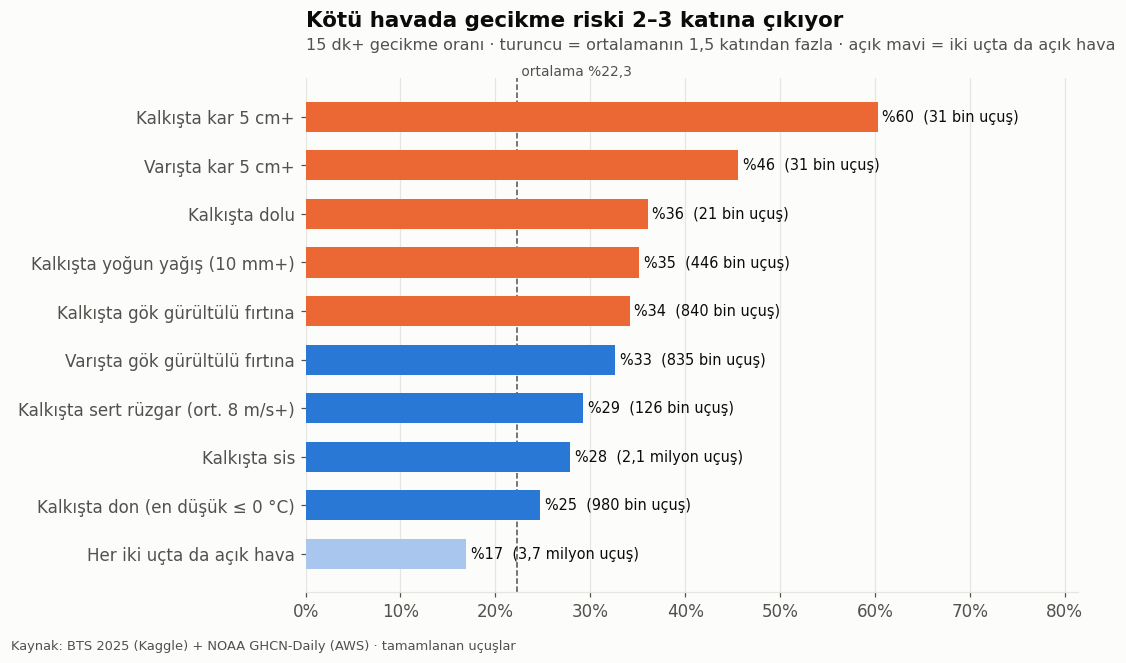

Kaydedildi: figures/07_hava_durumu.png


In [9]:
conds = [
    ('Kalkışta kar 5 cm+', 'o_snow_mm >= 50'),
    ('Varışta kar 5 cm+', 'd_snow_mm >= 50'),
    ('Kalkışta gök gürültülü fırtına', 'o_thunder = 1'),
    ('Varışta gök gürültülü fırtına', 'd_thunder = 1'),
    ('Kalkışta yoğun yağış (10 mm+)', 'o_heavy_rain = 1'),
    ('Kalkışta sert rüzgar (ort. 8 m/s+)', 'o_awnd_ms >= 8'),
    ('Kalkışta don (en düşük ≤ 0 °C)', 'o_freezing = 1'),
    ('Kalkışta sis', 'o_fog = 1'),
    ('Kalkışta dolu', 'o_hail = 1'),
    ('Her iki uçta da açık hava', "o_prcp_mm = 0 AND d_prcp_mm = 0 AND o_thunder = 0 AND d_thunder = 0 AND coalesce(o_snow_mm, 0) = 0"),
]
rows = []
for name, cond in conds:
    n, rate = con.sql(f'SELECT count(*), avg(target_arr_del15) FROM t WHERE {cond}').fetchone()
    rows.append((name, n, rate))
w = pd.DataFrame(rows, columns=['kosul', 'ucus', 'oran']).sort_values('oran')
print(w.assign(oran=(w['oran'] * 100).round(1), kat=(w['oran'] / BASE_RATE).round(2)).to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
colors = [MUTED_BAR if 'açık hava' in k else (ORANGE if v >= BASE_RATE * 1.5 else BLUE) for k, v in zip(w['kosul'], w['oran'])]
ax.barh(w['kosul'], w['oran'], height=0.62, color=colors, zorder=2)
for y, (v, n) in enumerate(zip(w['oran'], w['ucus'])):
    ax.text(v + 0.005, y, f'%{v * 100:.0f}  ({fmt_n(n)} uçuş)', va='center', color=INK, fontsize=9.5)
baseline(ax, horizontal=True)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, w['oran'].max() * 1.35)
ax.set_title('Kötü havada gecikme riski 2–3 katına çıkıyor')
finish(fig, ax, '07_hava_durumu', subtitle='15 dk+ gecikme oranı · turuncu = ortalamanın 1,5 katından fazla · açık mavi = iki uçta da açık hava')

       kar    ucus  oran
ölçülmüyor 1149570  18.7
         0 5570246  22.4
  0–2,5 cm   92901  38.9
  2,5–5 cm   35346  48.7
   5–10 cm   22665  55.1
    10 cm+    8757  73.6


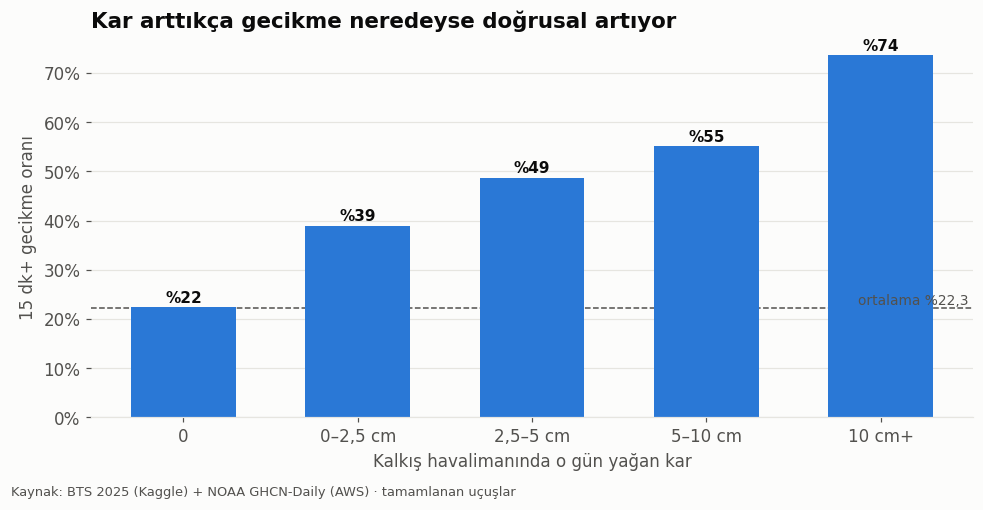

Kaydedildi: figures/08_kar.png


In [10]:
s = con.sql('''SELECT CASE WHEN o_snow_mm IS NULL THEN 'ölçülmüyor' WHEN o_snow_mm = 0 THEN '0'
                           WHEN o_snow_mm < 25 THEN '0–2,5 cm' WHEN o_snow_mm < 50 THEN '2,5–5 cm'
                           WHEN o_snow_mm < 100 THEN '5–10 cm' ELSE '10 cm+' END AS kar,
                      min(coalesce(o_snow_mm, -1)) AS sira, count(*) AS ucus, avg(target_arr_del15) AS oran
               FROM t GROUP BY 1 ORDER BY sira''').df()
print(s.drop(columns='sira').assign(oran=(s['oran'] * 100).round(1)).to_string(index=False))
s = s[s['kar'] != 'ölçülmüyor']
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.bar(s['kar'], s['oran'], width=0.6, color=BLUE, zorder=2)
for x, v in enumerate(s['oran']):
    ax.text(x, v + 0.01, f'%{v * 100:.0f}', ha='center', color=INK, fontsize=10, fontweight='bold')
baseline(ax)
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel('Kalkış havalimanında o gün yağan kar')
ax.set_ylabel('15 dk+ gecikme oranı')
ax.set_title('Kar arttıkça gecikme neredeyse doğrusal artıyor')
finish(fig, ax, '08_kar')

**Yorum — hava durumu (eklediğimiz NOAA tablosunun katkısı)**
- **Kar** en güçlü hava etkisi: kalkışta 5 cm+ kar → gecikme **%60** (ortalamanın **2,7 katı**); 10 cm üstünde **%74**. İlişki kar miktarıyla neredeyse doğrusal artıyor.
- **Kalkıştaki hava, varıştakinden daha etkili** (kar: %60'a karşı %46; fırtına: %34'e karşı %33). Mantıklı: kötü hava kalkışta buzlanma önleme (de-icing), yer işlemleri ve kalkış sırası gecikmesi yaratıyor.
- Gök gürültülü fırtına, yoğun yağış ve dolu → ortalamanın **~1,5 katı**. Bu olaylar yazın çok sık (fırtınalı gün sayısı yüksek) → yaz zirvesinin açıklaması.
- **Her iki uçta da açık hava** → gecikme sadece **%17** (ortalamanın altında). Kötü hava ile iyi hava arasında 3,5 kata varan fark var.
- Kar ölçülmeyen istasyonlarda (sıcak bölgeler) gecikme %18,7 → boş değeri "0" ile doldurmamak doğru karardı: "ölçülmüyor" kendi başına bilgi taşıyor (sıcak iklim).
- Not: Sis (WT01) çok geniş tanımlı (pus/hafif sis dahil, uçuşların %31'inde işaretli) → etkisi zayıf (%28). Modelde tutacağız ama ağırlığı düşük olabilir.

## 5. Gecikmenin sebepleri ve iptaller (sadece analiz — `post_` sütunları)
BTS, 15 dk+ geciken uçuşlarda gecikme dakikalarını beş sebebe dağıtıyor. Bu bilgi uçuştan **sonra** belli olduğu için modelde yok,
ama "neden gecikiyor?" sorusunun cevabı.

Güvenlik                                0.1
Aşırı hava olayı                        6.4
Hava trafik sistemi (yoğunluk, ATC)    21.9
Havayolu (bakım, ekip, yükleme)        32.5
Uçağın önceki seferi geç geldi         39.2


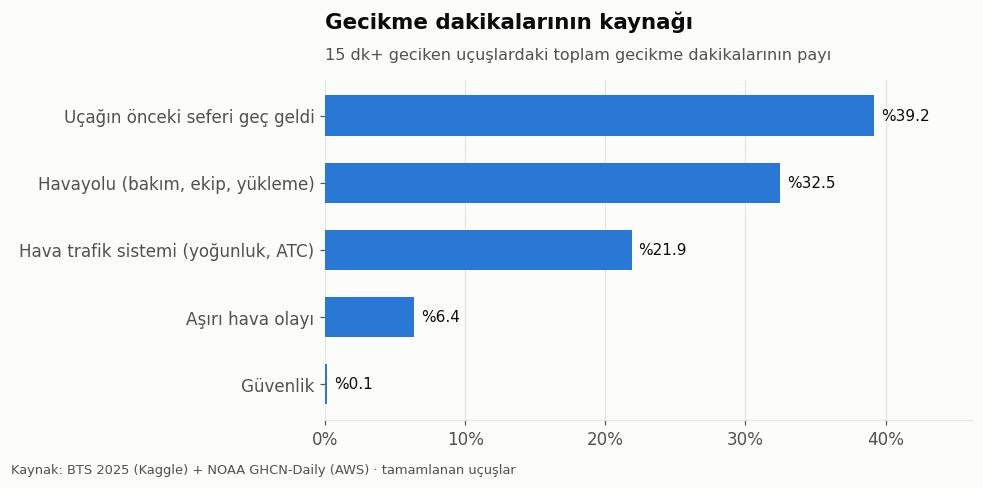

Kaydedildi: figures/09_gecikme_sebepleri.png

Not: "Aşırı hava olayı" payı küçük görünüyor, çünkü BTS hava kaynaklı gecikmelerin çoğunu "hava trafik sistemi" altında sayıyor.


In [11]:
c = con.sql('''SELECT sum(post_carrier_delay_min) AS "Havayolu (bakım, ekip, yükleme)",
                      sum(post_late_aircraft_delay_min) AS "Uçağın önceki seferi geç geldi",
                      sum(post_nas_delay_min) AS "Hava trafik sistemi (yoğunluk, ATC)",
                      sum(post_weather_delay_min) AS "Aşırı hava olayı",
                      sum(post_security_delay_min) AS "Güvenlik"
               FROM t WHERE target_arr_del15 = 1''').df().T[0]
c = (c / c.sum()).sort_values()
print((c * 100).round(1).to_string())
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.barh(c.index, c.values, height=0.6, color=BLUE, zorder=2)
for y, v in enumerate(c.values):
    ax.text(v + 0.005, y, f'%{v * 100:.1f}', va='center', color=INK, fontsize=10)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, c.max() * 1.18)
ax.set_title('Gecikme dakikalarının kaynağı')
finish(fig, ax, '09_gecikme_sebepleri', subtitle='15 dk+ geciken uçuşlardaki toplam gecikme dakikalarının payı')
print('\nNot: "Aşırı hava olayı" payı küçük görünüyor, çünkü BTS hava kaynaklı gecikmelerin çoğunu "hava trafik sistemi" altında sayıyor.')

kod  ucus               sebep      pay
  D    50            Güvenlik 0.000486
  C 18349 Hava trafik sistemi 0.178360
  A 21073            Havayolu 0.204839
  B 63404         Hava durumu 0.616315


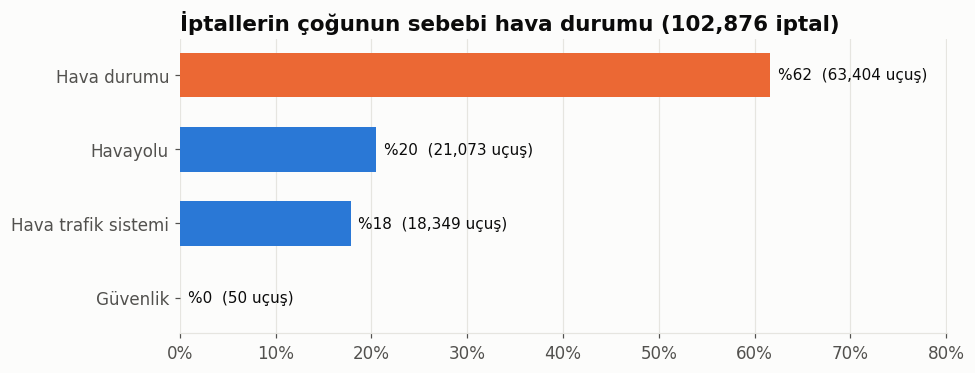

Kaydedildi: figures/10_iptal_sebepleri.png


In [12]:
ip = con.sql('''SELECT post_cancellation_code AS kod, count(*) AS ucus FROM f WHERE status = 'iptal' GROUP BY 1''').df()
ip['sebep'] = ip['kod'].map({'A': 'Havayolu', 'B': 'Hava durumu', 'C': 'Hava trafik sistemi', 'D': 'Güvenlik'})
ip['pay'] = ip['ucus'] / ip['ucus'].sum()
ip = ip.sort_values('pay')
print(ip.to_string(index=False))
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.barh(ip['sebep'], ip['pay'], height=0.6, color=[ORANGE if s == 'Hava durumu' else BLUE for s in ip['sebep']], zorder=2)
for y, (v, n) in enumerate(zip(ip['pay'], ip['ucus'])):
    ax.text(v + 0.008, y, f'%{v * 100:.0f}  ({n:,} uçuş)', va='center', color=INK, fontsize=10)
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(PCT)
ax.set_xlim(0, ip['pay'].max() * 1.3)
ax.set_title(f'İptallerin çoğunun sebebi hava durumu ({ip["ucus"].sum():,} iptal)')
finish(fig, ax, '10_iptal_sebepleri', source=False)

**Yorum — sebepler ve iptaller** (sadece analiz; bu sütunlar modelde yok)
- Gecikme dakikalarının **%39'u "uçağın önceki seferi geç geldi"** → domino etkisinin doğrudan kanıtı. **%33 havayolu kaynaklı** (bakım, ekip, yükleme), **%22 hava trafik sistemi**, **%6 aşırı hava olayı**.
- "Aşırı hava olayı" payının küçük olması yanıltıcı: BTS, havanın hava trafik sistemini yavaşlattığı durumları "hava trafik sistemi" altında sayıyor. Yani havanın gerçek etkisi %6'dan çok daha büyük — Bölüm 4'teki grafikler de bunu gösteriyor.
- **İptallerin %62'si hava durumu kaynaklı** (63.404 iptal). Hava durumu, gecikmeden çok iptali belirliyor.
- **Sınırlama:** Veride uçak kuyruk numarası olmadığı için "aynı uçağın bir önceki seferi geç kaldı mı?" bilgisini modele doğrudan veremiyoruz. Bunun yerine kalkış saatini (gün içindeki sıra) kullanıyoruz — sonraki adımlar listesine yazılacak.

## 6. Diğer değişkenler: yoğunluk, tatil, haftanın günü, mesafe

In [13]:
GUNLER = {1: 'Pzt', 2: 'Sal', 3: 'Çar', 4: 'Per', 5: 'Cum', 6: 'Cmt', 7: 'Paz'}
dw = con.sql('SELECT day_of_week, count(*) AS ucus, round(avg(target_arr_del15) * 100, 1) AS gecikme_yuzde FROM t GROUP BY 1 ORDER BY 1').df()
dw['gun'] = dw['day_of_week'].map(GUNLER)
print('Haftanın günü:'); print(dw[['gun', 'ucus', 'gecikme_yuzde']].to_string(index=False))

print('\nKalkış havalimanının o saatteki planlı kalkış sayısı:')
print(con.sql('''SELECT CASE WHEN origin_sched_dep_hour <= 5 THEN '1-5' WHEN origin_sched_dep_hour <= 15 THEN '6-15'
                             WHEN origin_sched_dep_hour <= 30 THEN '16-30' WHEN origin_sched_dep_hour <= 50 THEN '31-50' ELSE '50+' END AS yogunluk,
                        count(*) AS ucus, round(avg(target_arr_del15) * 100, 1) AS gecikme_yuzde
                 FROM t GROUP BY 1 ORDER BY min(origin_sched_dep_hour)''').df().to_string(index=False))

print('\nResmî tatile uzaklık:')
print(con.sql('''SELECT days_to_holiday AS gun, count(*) AS ucus, round(avg(target_arr_del15) * 100, 1) AS gecikme_yuzde
                 FROM t GROUP BY 1 ORDER BY 1''').df().to_string(index=False))

print('\nMesafe (mil):')
print(con.sql('''SELECT CASE WHEN distance_mi < 300 THEN '<300' WHEN distance_mi < 600 THEN '300-600' WHEN distance_mi < 1000 THEN '600-1000'
                             WHEN distance_mi < 2000 THEN '1000-2000' ELSE '2000+' END AS mesafe,
                        count(*) AS ucus, round(avg(target_arr_del15) * 100, 1) AS gecikme_yuzde
                 FROM t GROUP BY 1 ORDER BY min(distance_mi)''').df().to_string(index=False))

Haftanın günü:
gun    ucus  gecikme_yuzde
Pzt 1031857           23.8
Sal  931999           18.4
Çar  951705           19.3
Per 1021742           23.3
Cum 1024839           23.3
Cmt  890641           21.0
Paz 1026702           26.4

Kalkış havalimanının o saatteki planlı kalkış sayısı:
yogunluk    ucus  gecikme_yuzde
     1-5 1403006           20.6
    6-15 1604703           20.2
   16-30 1868900           23.2
   31-50 1097655           22.9
     50+  905221           26.1

Resmî tatile uzaklık:
 gun    ucus  gecikme_yuzde
   0  195392           23.3
   1  400388           24.0
   2  400305           24.6
   3  430748           26.3
   4  392413           23.7
   5  359689           22.8
   6  374187           22.4
   7  387424           21.6
   8  310680           19.1
   9  275354           19.4
  10  273103           23.8
  11  272548           23.9
  12  225017           19.3
  13  224630           18.4
  14 2357607           21.7

Mesafe (mil):
   mesafe    ucus  gecikme_yuzde
   

**Yorum — diğer değişkenler**
- **Haftanın günü:** Pazar (%26,4), Pazartesi (%23,8), Perşembe–Cuma (%23,3) yüksek; Salı (%18,4) ve Çarşamba (%19,3) en dakik → hafta sonu dönüş ve iş seyahati günleri yoğun.
- **Havalimanı yoğunluğu:** O saatte 50+ kalkış planlanan havalimanlarında %26,1, sakin saatlerde %20,6 → etkisi var ama orta düzeyde (yoğun havalimanları kapasitesini buna göre kurmuş).
- **Tatil:** Resmî tatilden 1–3 gün uzaklıkta gecikme %24–26, 8–9 gün uzaklıkta %19 → tatil öncesi/sonrası seyahat yoğunluğu. Tatil gününün kendisi (%23) daha sakin.
- **Mesafe:** Etkisi zayıf (%21–23 arası) → uzun uçuşta havada süre kazanılabiliyor; mesafeyi modelde tutacağız ama güçlü bir sinyal beklemiyoruz.
- **Kaba önem sıralaması (en riskli – en güvenli grup farkı):** Kalkış saati (24 puan) > kalkışta kar (23) > kalkış havalimanı (22) > fırtına (13) > ay (12) > havayolu (11) > haftanın günü (8) > tatil (8). Model sonrası gerçek değişken önemiyle karşılaştıracağız.

## 7. Özet: hangi değişken target'la ne kadar ilişkili?
Her değişken için "en riskli grup" ile "en güvenli grup" arasındaki gecikme oranı farkı (kaba bir önem ölçüsü; model sonrası gerçek önemle karşılaştıracağız).

In [14]:
summary = []
for name, expr in [('Kalkış saati', 'dep_hour'), ('Ay', 'month'), ('Havayolu', 'airline'), ('Haftanın günü', 'day_of_week'),
                   ('Kalkışta fırtına', 'o_thunder'), ('Kalkışta kar günü', 'o_snow_day'), ('Varışta fırtına', 'd_thunder'),
                   ('Tatile uzaklık', 'days_to_holiday'), ('Kalkış havalimanı', 'origin')]:
    g = con.sql(f'''SELECT {expr} AS g, count(*) AS n, avg(target_arr_del15) AS r FROM t
                    WHERE {expr} IS NOT NULL GROUP BY 1 HAVING count(*) >= 0.001 * (SELECT count(*) FROM t)''').df()
    summary.append((name, g['r'].min(), g['r'].max(), g['r'].max() - g['r'].min()))
sm = pd.DataFrame(summary, columns=['degisken', 'en_dusuk', 'en_yuksek', 'fark']).sort_values('fark', ascending=False)
print(sm.assign(en_dusuk=(sm['en_dusuk'] * 100).round(1), en_yuksek=(sm['en_yuksek'] * 100).round(1),
                fark=(sm['fark'] * 100).round(1)).to_string(index=False))
print('\nGrafikler:', sorted(p.name for p in FIG.glob('*.png')))

         degisken  en_dusuk  en_yuksek  fark
     Kalkış saati       8.9       32.6  23.7
Kalkışta kar günü      22.4       45.3  22.9
Kalkış havalimanı      12.4       34.4  22.0
 Kalkışta fırtına      20.7       34.1  13.5
               Ay      16.6       28.9  12.3
  Varışta fırtına      20.9       32.6  11.8
         Havayolu      17.3       27.9  10.6
    Haftanın günü      18.4       26.4   8.0
   Tatile uzaklık      18.4       26.3   7.9

Grafikler: ['01_gecikme_dagilimi.png', '02_aylara_gore.png', '03_saate_gore.png', '04_ay_saat_isi_haritasi.png', '05_havayollari.png', '06_havalimanlari.png', '07_hava_durumu.png', '08_kar.png', '09_gecikme_sebepleri.png', '10_iptal_sebepleri.png']


## Sunum için 5 ana bulgu
1. **Domino etkisi:** Sabah 05:00 uçuşlarında gecikme %9, akşam 19:00'da %33 — gecikme gün boyunca birikiyor (gecikme dakikalarının %39'u "önceki sefer geç geldi").
2. **Kar ve fırtına:** Kalkışta 5 cm+ kar gecikme riskini 2,7 katına çıkarıyor; iki uçta da açık havada risk sadece %17. İptallerin %62'si hava kaynaklı.
3. **Mevsim:** Yaz akşamları en riskli an (≈%45); Eylül en dakik ay.
4. **Havayolu ve havalimanı:** Havayolları arasında 10 puan fark (Hawaiian/Delta ↔ Frontier/American); en riskli büyük havalimanı Dallas/Fort Worth.
5. **Hedef tanımı doğru:** Uçuşların %60'ı erken iniyor; gecikme olduğunda uzun kuyruk var → "15 dk'yı geçecek mi?" sınıflandırması, dakika tahmininden daha sağlam ve iş açısından anlamlı.

## Bitti
**Dosya → İndir → .ipynb** ile indirip gönder. Sonraki adım: modelleme (baseline → lojistik regresyon → LightGBM) ve zamana göre bölme.